In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.metrics import roc_auc_score

In [2]:
confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3.csv')

In [3]:
sequences = pd.read_csv('../data/interim/sequences.csv', index_col='tcr_id')

In [4]:
confidence_scores = confidence_scores.merge(sequences, how='inner', left_on='tcr_id', right_index=True)

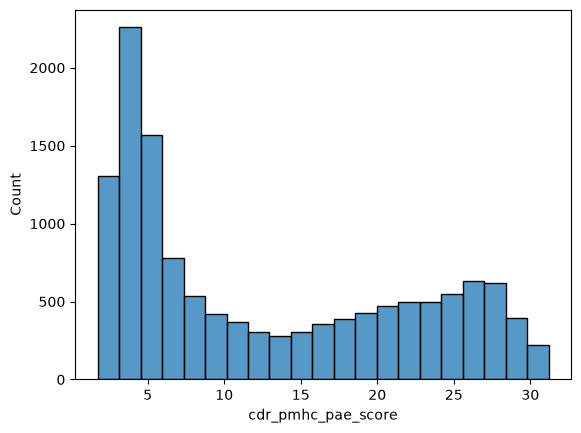

In [5]:
sns.histplot(confidence_scores, x='cdr_pmhc_pae_score')
plt.show()

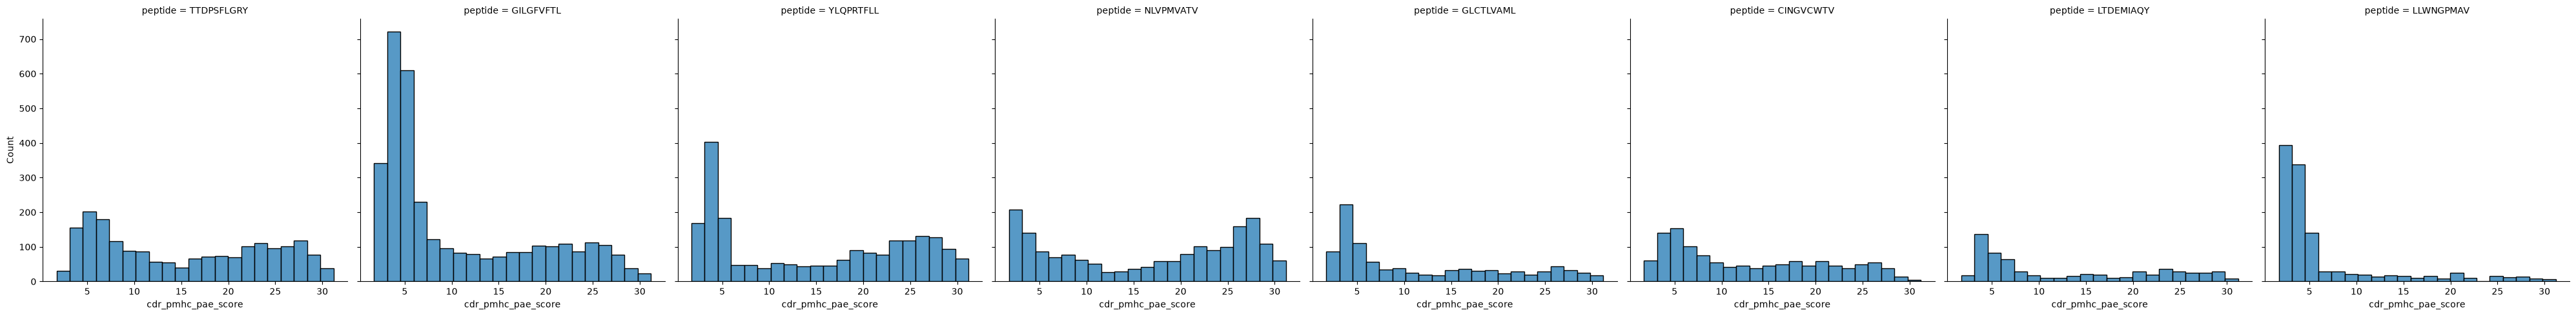

In [6]:
sns.displot(confidence_scores, x='cdr_pmhc_pae_score', col='peptide')
plt.show()

In [7]:
confidence_scores_agg = confidence_scores.groupby('tcr_id').agg({'cdr_pmhc_pae_score': 'median'})
confidence_scores_agg = confidence_scores_agg.merge(
    sequences[['peptide']], how='inner', left_index=True, right_index=True
)

In [8]:
public_labels = pd.read_csv('../data/external/ttd_gil_ylq_nlv_glc_01-10-2026_TCRvdb.csv', index_col='tcr_id')

In [9]:
confidence_scores_public = confidence_scores_agg.merge(
    public_labels.query('ambiguous == 0'), how='inner', left_on='tcr_id', right_index=True
)

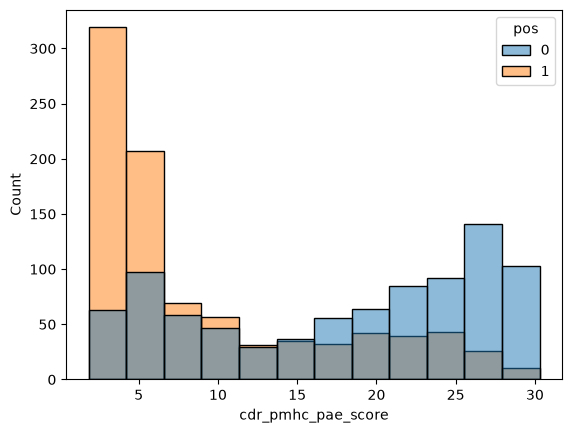

In [10]:
sns.histplot(confidence_scores_public, x='cdr_pmhc_pae_score', hue='pos', multiple='layer')
plt.show()

In [11]:
print(
    'CDR:pMHC PAE Score:',
    1 - roc_auc_score(confidence_scores_public['pos'], confidence_scores_public['cdr_pmhc_pae_score']),
)

CDR:pMHC PAE Score: 0.7788033067849581


In [12]:
per_peptide_performance = (
    confidence_scores_public.groupby('epitope_aa')
    .apply(lambda group: 1 - roc_auc_score(group['pos'], group['cdr_pmhc_pae_score']), include_groups=False)
    .sort_values(ascending=False)
)

print(per_peptide_performance, end='\n\n')
print('Macro-averaged ROC-AUC for combined method:', per_peptide_performance.mean())

epitope_aa
YLQPRTFLL     0.875989
NLVPMVATV     0.813381
GLCTLVAML     0.738149
GILGFVFTL     0.722109
TTDPSFLGRY    0.688646
dtype: float64

Macro-averaged ROC-AUC for combined method: 0.767654950614841


In [13]:
distance_matrices = {}
for chain_type in ('alpha', 'beta'):
    for cdr_num in (1, 2, 3):
        distance_matrices[f'cdr{cdr_num}_{chain_type}'] = np.loadtxt(
            f'../data/processed/cdr{cdr_num}_{chain_type}_distance_matrix.txt', dtype=int
        )

In [14]:
distance_matrices_combined = np.zeros((len(sequences), len(sequences)), dtype=int)
for matrix in distance_matrices.values():
    distance_matrices_combined += matrix

In [15]:
confidence_scores_agg['distance_cluster'] = None

for peptide in sequences['peptide'].unique():
    mask = (sequences['peptide'] == peptide).to_numpy()
    peptide_distances = distance_matrices_combined[np.ix_(mask, mask)]

    clusters = DBSCAN(eps=15, metric='precomputed').fit_predict(peptide_distances)
    clusters = clusters.astype(str)
    clusters = np.array([cluster if cluster != '-1' else 'None' for cluster in clusters])

    confidence_scores_agg.loc[mask, 'distance_cluster'] = clusters

In [16]:
clustered_scores = (
    confidence_scores_agg.query("distance_cluster != 'None'")
    .groupby(['peptide', 'distance_cluster'])['cdr_pmhc_pae_score']
    .transform('median')
)

confidence_scores_agg['cdr_pmhc_pae_score_clustered'] = confidence_scores_agg['cdr_pmhc_pae_score']
confidence_scores_agg.loc[clustered_scores.index, 'cdr_pmhc_pae_score_clustered'] = clustered_scores

In [17]:
confidence_scores_public = confidence_scores_agg.merge(
    public_labels.query('ambiguous == 0'), how='inner', left_on='tcr_id', right_index=True
)

In [18]:
print(
    'CDR:pMHC PAE Score:',
    1 - roc_auc_score(confidence_scores_public['pos'], confidence_scores_public['cdr_pmhc_pae_score_clustered']),
)

CDR:pMHC PAE Score: 0.7103872618207481


In [19]:
per_peptide_performance = (
    confidence_scores_public.groupby('epitope_aa')
    .apply(lambda group: 1 - roc_auc_score(group['pos'], group['cdr_pmhc_pae_score_clustered']), include_groups=False)
    .sort_values(ascending=False)
)

print(per_peptide_performance, end='\n\n')
print('Macro-averaged ROC-AUC for combined method:', per_peptide_performance.mean())

epitope_aa
YLQPRTFLL     0.739574
NLVPMVATV     0.685525
GLCTLVAML     0.653166
GILGFVFTL     0.634271
TTDPSFLGRY    0.633276
dtype: float64

Macro-averaged ROC-AUC for combined method: 0.6691622789976114


In [20]:
predictions = 1 - (confidence_scores_agg['cdr_pmhc_pae_score'] / confidence_scores_agg['cdr_pmhc_pae_score'].max())
predictions.name = 'prediction'

predictions = predictions.to_frame()

In [21]:
predictions.to_csv('../data/processed/alphafold_predictions.csv', index=True)